<h1 style="text-align:center;">Portfolio Risk Analysis Using Python</h1>

<h3 style="text-align:center;">Quantitative Risk Assessment of an Equal-Weighted NSE Stock Portfolio</h3>

<hr>

<h2 style="color:#2874A6;">1. Importing Libraries</h2>
<p>Importing the Python libraries required for data collection, numerical analysis, data manipulation and visualization.</p>

In [1]:
import numpy as np

import pandas as pd

import yfinance as yf

import matplotlib.pyplot as plt

import seaborn as sns

<h2 style="color:#2874A6;">2. Data Collection</h2>
<p>Retrieving five years of historical daily stock price data for the selected NSE-listed companies using Yahoo Finance.</p>

In [2]:
stocks = [
    "HDFCBANK.NS",
    "TCS.NS",
    "HINDUNILVR.NS",
    "RELIANCE.NS",
    "M&M.NS"
]

data = yf.download(
    stocks,
    period="5y",
    interval="1d",
    auto_adjust=True
)

[*********************100%***********************]  5 of 5 completed


In [3]:
data.head()

Price            Close                                                      \
Ticker     HDFCBANK.NS HINDUNILVR.NS      M&M.NS  RELIANCE.NS       TCS.NS   
Date                                                                         
2021-11-12  726.646729   2197.884521  895.325623  1174.461548  3052.723145   
2021-11-15  728.635315   2215.979736  886.351379  1167.531982  3076.314941   
2021-11-16  724.307251   2199.437988  916.806580  1140.402100  3078.999023   
2021-11-17  716.259277   2185.272705  911.221558  1115.989746  3049.130127   
2021-11-18  720.283325   2192.812256  881.864258  1120.201782  3009.132324   

Price             High                                                      \
Ticker     HDFCBANK.NS HINDUNILVR.NS      M&M.NS  RELIANCE.NS       TCS.NS   
Date                                                                         
2021-11-12  729.477539   2205.789893  896.948639  1177.020603  3059.735697   
2021-11-15  735.466625   2220.777713  905.588720  1178.583205  3090.426917   
2021-11-16  728.611897   2225.027196  922.200706  1166.263636  3095.578509   
2021-11-17  722.435517   2202.545555  934.659640  1131.819203  3084.583285   
2021-11-18  722.201699   2199.164041  911.746622  1127.312650  3048.221649   

Price       ...        Open                                         \
Ticker      ... HDFCBANK.NS HINDUNILVR.NS      M&M.NS  RELIANCE.NS   
Date        ...                                                      
2021-11-12  ...  725.243032   2182.393956  891.697742  1160.783464   
2021-11-15  ...  730.904612   2197.107785  892.652432  1177.586705   
2021-11-16  ...  727.582542   2225.027196  886.351413  1164.927503   
2021-11-17  ...  719.113448   2197.016414  916.472454  1131.819203   
2021-11-18  ...  714.036888   2184.221682  911.746622  1114.177982   

Price                        Volume                                     \
Ticker           TCS.NS HDFCBANK.NS HINDUNILVR.NS   M&M.NS RELIANCE.NS   
Date                                                                     
2021-11-12  3035.364557    14914092       1651974  6239600     8712341   
2021-11-15  3054.411101     9533594       1007999  3757546     4803269   
2021-11-16  3089.907720     8245406       1245209  7368780    11337581   
2021-11-17  3073.977690     7598878        956809  5416608    10202029   
2021-11-18  3043.286631     9152874       1236943  3463426     8505625   

Price                
Ticker       TCS.NS  
Date                 
2021-11-12  1747259  
2021-11-15  1809157  
2021-11-16  2013204  
2021-11-17  1632914  
2021-11-18  2136598  

[5 rows x 25 columns]

<h2 style="color:#2874A6;">3. Data Preprocessing</h2>
<p>Extracting closing prices, checking for missing values and preparing the dataset for financial return calculations.</p>

In [5]:
prices = data["Close"]

prices.head()

Ticker,HDFCBANK.NS,HINDUNILVR.NS,M&M.NS,RELIANCE.NS,TCS.NS
Date,,,,,
2021-11-12,726.646729,2197.884521,895.325623,1174.461548,3052.723145
2021-11-15,728.635315,2215.979736,886.351379,1167.531982,3076.314941
2021-11-16,724.307251,2199.437988,916.806580,1140.402100,3078.999023
2021-11-17,716.259277,2185.272705,911.221558,1115.989746,3049.130127
2021-11-18,720.283325,2192.812256,881.864258,1120.201782,3009.132324


<p>Checking the stock price dataset for missing values to identify incomplete observations.</p>

In [6]:
prices.isnull().sum()

Ticker
HDFCBANK.NS      0
HINDUNILVR.NS    0
M&M.NS           0
RELIANCE.NS      0
TCS.NS           0
dtype: int64

<p>Removing rows containing missing values to ensure a complete dataset for return calculations.</p>

In [7]:
prices = prices.dropna()

In [8]:
prices.shape

(1236, 5)

<h2 style="color:#2874A6;">4. Exploratory Data Analysis</h2>
<p>Examining historical stock returns, volatility and correlations to understand individual stock behaviour and relationships within the portfolio.</p>

<p>Calculating daily percentage returns for each stock using consecutive adjusted closing prices.</p>

In [10]:
daily_returns = prices.pct_change(fill_method=None).dropna()

daily_returns.head()

Ticker,HDFCBANK.NS,HINDUNILVR.NS,M&M.NS,RELIANCE.NS,TCS.NS
Date,,,,,
2021-11-15,0.002737,0.008233,-0.010023,-0.005900,0.007728
2021-11-16,-0.005940,-0.007465,0.034360,-0.023237,0.000872
2021-11-17,-0.011111,-0.006440,-0.006092,-0.021407,-0.009701
2021-11-18,0.005618,0.003450,-0.032218,0.003774,-0.013118
2021-11-22,-0.015623,-0.004522,-0.024737,-0.044293,-0.004977


<p>Calculating the average daily return and standard deviation of daily returns for each stock.</p>

In [11]:
average_returns = daily_returns.mean()

average_returns

Ticker
HDFCBANK.NS      0.000180
HINDUNILVR.NS   -0.000002
M&M.NS           0.001237
RELIANCE.NS      0.000210
TCS.NS          -0.000077
dtype: float64

In [12]:
daily_volatility = daily_returns.std()

daily_volatility

Ticker
HDFCBANK.NS      0.013365
HINDUNILVR.NS    0.013018
M&M.NS           0.017696
RELIANCE.NS      0.014436
TCS.NS           0.014431
dtype: float64

In [13]:
risk_summary = pd.DataFrame({
    "Average Daily Return": average_returns,
    "Daily Volatility": daily_volatility
})

risk_summary

,Average Daily Return,Daily Volatility
Ticker,,
HDFCBANK.NS,0.000180,0.013365
HINDUNILVR.NS,-0.000002,0.013018
M&M.NS,0.001237,0.017696
RELIANCE.NS,0.000210,0.014436
TCS.NS,-0.000077,0.014431


<p>Calculating the correlation between daily returns of the selected stocks to understand how their price movements are related.</p>

In [14]:
correlation_matrix = daily_returns.corr()

correlation_matrix

Ticker,HDFCBANK.NS,HINDUNILVR.NS,M&M.NS,RELIANCE.NS,TCS.NS
Ticker,,,,,
HDFCBANK.NS,1.000000,0.241380,0.368232,0.365952,0.237198
HINDUNILVR.NS,0.241380,1.000000,0.268242,0.228481,0.206742
M&M.NS,0.368232,0.268242,1.000000,0.358810,0.235585
RELIANCE.NS,0.365952,0.228481,0.358810,1.000000,0.257339
TCS.NS,0.237198,0.206742,0.235585,0.257339,1.000000


<p>Visualizing the correlation matrix using a heatmap to identify positive and negative relationships between stocks.</p>

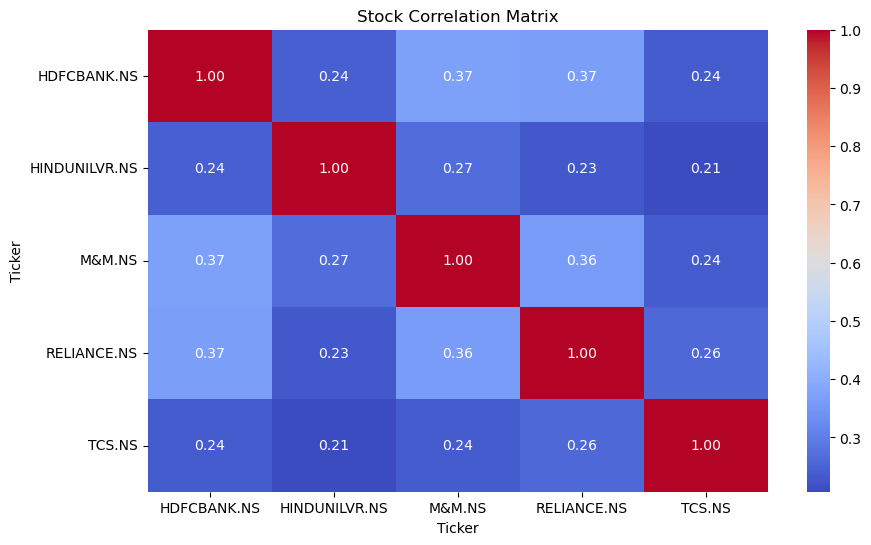

In [15]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Stock Correlation Matrix")
plt.show()

<h2 style="color:#2874A6;">5. Portfolio Construction</h2>
<p>Constructing an equal-weighted portfolio of five selected NSE stocks, with an assumed initial investment of ₹10,00,000.</p>

<p>Assigning an equal portfolio weight of 20% to each of the five selected stocks.</p>

In [16]:
weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

<p>Calculating daily portfolio returns by combining individual stock returns using their assigned portfolio weights.</p>

In [17]:
portfolio_returns = daily_returns.dot(weights)

In [18]:
portfolio_returns.head()

Date
2021-11-15    0.000555
2021-11-16   -0.000282
2021-11-17   -0.010950
2021-11-18   -0.006499
2021-11-22   -0.018831
dtype: float64

In [19]:
portfolio_returns.mean()

np.float64(0.0003095732016790315)

<h2 style="color:#2874A6;">6. Portfolio Volatility Analysis</h2>
<p>Measuring the portfolio's daily and annualized volatility to assess its overall return variability.</p>

<p>Calculating the portfolio's daily volatility and annualizing it using 252 trading days.</p>

In [20]:
portfolio_volatility = portfolio_returns.std()

portfolio_volatility

0.009522036138054758

In [21]:
annualized_volatility = portfolio_volatility * np.sqrt(252)

annualized_volatility

np.float64(0.15115763757757672)

In [22]:
print("Daily Portfolio Volatility:", portfolio_volatility)

print("Annualized Portfolio Volatility:", annualized_volatility)

Daily Portfolio Volatility: 0.009522036138054758
Annualized Portfolio Volatility: 0.15115763757757672


<h2 style="color:#2874A6;">7. Value at Risk (VaR) Analysis</h2>
<p>Estimating potential portfolio losses at 95% and 99% confidence levels using three different VaR methodologies.</p>

<h3 style="color:#555;">7.1 Parametric VaR</h3>
<p>Estimating potential portfolio losses using the normal distribution, portfolio volatility and mean return.</p>

<p>Defining the assumed initial portfolio value, average daily return and Z-scores for the 95% and 99% confidence levels.</p>

In [24]:
# define portfolio value

portfolio_value = 1000000

In [25]:
# calculate the daily average portfolio return

portfolio_mean = portfolio_returns.mean()

portfolio_mean

np.float64(0.0003095732016790315)

In [27]:
# define z scores for our confidence levels

z_95 = 1.645
z_99 = 2.326

<p>Calculating one-day Parametric VaR at 95% and 99% confidence levels using the normal distribution assumption.</p>

<p>Calculating one-day Parametric VaR at 95% and 99% confidence levels using the normal distribution assumption.</p>

In [28]:
# calculate var

var_95 = portfolio_value * (
    z_95 * portfolio_volatility - portfolio_mean
)

var_99 = portfolio_value * (
    z_99 * portfolio_volatility - portfolio_mean
)

In [29]:
print("95% Parametric VaR:", var_95)

print("99% Parametric VaR:", var_99)

95% Parametric VaR: 15354.176245421046
99% Parametric VaR: 21838.682855436335


<h3 style="color:#555;">7.2 Historical VaR</h3>
<p>Estimating potential portfolio losses using the historical distribution of observed portfolio returns.</p>

<p>Converting historical portfolio returns into monetary losses and estimating VaR using the 95th and 99th percentiles of the observed loss distribution.</p>

In [31]:
# Convert portfolio returns into daily monetary losses

historical_losses = -portfolio_returns * portfolio_value

# Calculate Historical VaR

historical_var_95 = np.percentile(historical_losses, 95)

historical_var_99 = np.percentile(historical_losses, 99)

In [32]:
print("95% Historical VaR:", historical_var_95)

print("99% Historical VaR:", historical_var_99)

95% Historical VaR: 15245.951669243328
99% Historical VaR: 23224.7250041206


<h3 style="color:#555;">7.3 Monte Carlo VaR</h3>
<p>Estimating potential portfolio losses through simulated returns generated using historical means and covariance.</p>

<p>Calculating the covariance matrix of stock returns to capture their individual volatilities and relationships for Monte Carlo simulation.</p>

In [34]:
# calculate covariance matrix

cov_matrix = daily_returns.cov()

<p>Generating 10,000 simulated daily stock return scenarios using historical mean returns and the covariance matrix.</p>

In [35]:
simulations = np.random.multivariate_normal(
    mean=daily_returns.mean(),
    cov=cov_matrix,
    size=10000
)

In [36]:
simulated_portfolio_returns = simulations @ weights

In [37]:
simulated_losses = -simulated_portfolio_returns * portfolio_value

<p>Calculating simulated portfolio returns and estimating Monte Carlo VaR at 95% and 99% confidence levels.</p>

In [38]:
monte_carlo_var_95 = np.percentile(simulated_losses, 95)

monte_carlo_var_99 = np.percentile(simulated_losses, 99)

print("95% Monte Carlo VaR:", monte_carlo_var_95)

print("99% Monte Carlo VaR:", monte_carlo_var_99)

95% Monte Carlo VaR: 15460.823302019819
99% Monte Carlo VaR: 22164.401128711503


<p>Consolidating and comparing the VaR estimates obtained from the three methodologies at 95% and 99% confidence levels.</p>

| Confidence Level | Parametric VaR | Historical VaR | Monte Carlo VaR |
|:---:|---:|---:|---:|
| 95% | ₹15,354.18 | ₹15,245.95 | ₹15,460.82 |
| 99% | ₹21,838.68 | ₹23,224.73 | ₹22,164.40 |

<h2 style="color:#2874A6;">8. Expected Shortfall (ES)</h2>
<p>Estimating the average portfolio loss beyond the VaR threshold at 95% and 99% confidence levels.</p>

<p>Calculating Expected Shortfall at 95% and 99% confidence levels by averaging losses that exceed the corresponding Historical VaR thresholds.</p>

In [42]:
# calculate 95% and 99% expected shortfall

expected_shortfall_95 = historical_losses[
    historical_losses >= historical_var_95
].mean()

expected_shortfall_99 = historical_losses[
    historical_losses >= historical_var_99
].mean()

print("95% Expected Shortfall:", expected_shortfall_95)

print("99% Expected Shortfall:", expected_shortfall_99)

95% Expected Shortfall: 20558.860283675967
99% Expected Shortfall: 29810.806491081035


<h2 style="color:#2874A6;">9. VaR Backtesting</h2>
<p>Evaluating the reliability of historical VaR estimates by comparing predicted risk thresholds with actual portfolio losses.</p>

<h3 style="color:#555;">9.1 Rolling Historical VaR</h3>
<p>Calculating VaR using a rolling 250-day historical estimation window.</p>

In [47]:
# calculate historical losses

# we already have that - historical_losses

<p>Calculating rolling 95% and 99% Historical VaR using the previous 250 trading days to estimate daily portfolio risk.</p>

In [48]:
# calculate rolling historical VaR

rolling_var_95 = historical_losses.shift(1).rolling(
    window=250
).quantile(0.95)

rolling_var_99 = historical_losses.shift(1).rolling(
    window=250
).quantile(0.99)

<h3 style="color:#555;">9.2 VaR Violation Analysis</h3>
<p>Identifying and measuring instances where actual portfolio losses exceed the estimated VaR thresholds.</p>

<p>Identifying days when actual portfolio losses exceeded the corresponding rolling VaR estimates.</p>

In [81]:
violations_95 = historical_losses > rolling_var_95

violations_99 = historical_losses > rolling_var_99

<p>Counting the total VaR violations at both confidence levels and identifying the number of valid backtesting days.</p>

In [80]:
# count VaR violations

total_violations_95 = violations_95.sum()

total_violations_99 = violations_99.sum()

total_days = rolling_var_95.notna().sum()

print("Total Backtesting Days:", total_days)

print("95% VaR Violations:", total_violations_95)

print("99% VaR Violations:", total_violations_99)

Total Backtesting Days: 985
95% VaR Violations: 58
99% VaR Violations: 15


<p>Calculating the percentage of backtesting days on which actual portfolio losses exceeded the estimated VaR thresholds.</p>

In [51]:
# calculate violation percentages

violation_rate_95 = total_violations_95 / total_days

violation_rate_99 = total_violations_99 / total_days

print("95% Violation Rate:", violation_rate_95)

print("99% Violation Rate:", violation_rate_99)

95% Violation Rate: 0.05888324873096447
99% Violation Rate: 0.015228426395939087


<h3 style="color:#555;">9.4 VaR Backtesting Results</h3>
<p>The rolling historical VaR model was backtested over 985 trading days using a 250-day estimation window.</p>

<ul>
<li>The 95% VaR model recorded a violation rate of 5.89%, compared with the expected 5%.</li>
<li>The 99% VaR model recorded a violation rate of 1.52%, compared with the expected 1%.</li>
</ul>

<p>Both rates were slightly higher than expected, suggesting some underestimation of portfolio risk.</p>

<h3 style="color:#555;">9.3 Backtesting Visualization</h3>

<p>Plotting actual daily portfolio losses against the rolling 95% VaR threshold to visually identify VaR violations over time.</p>

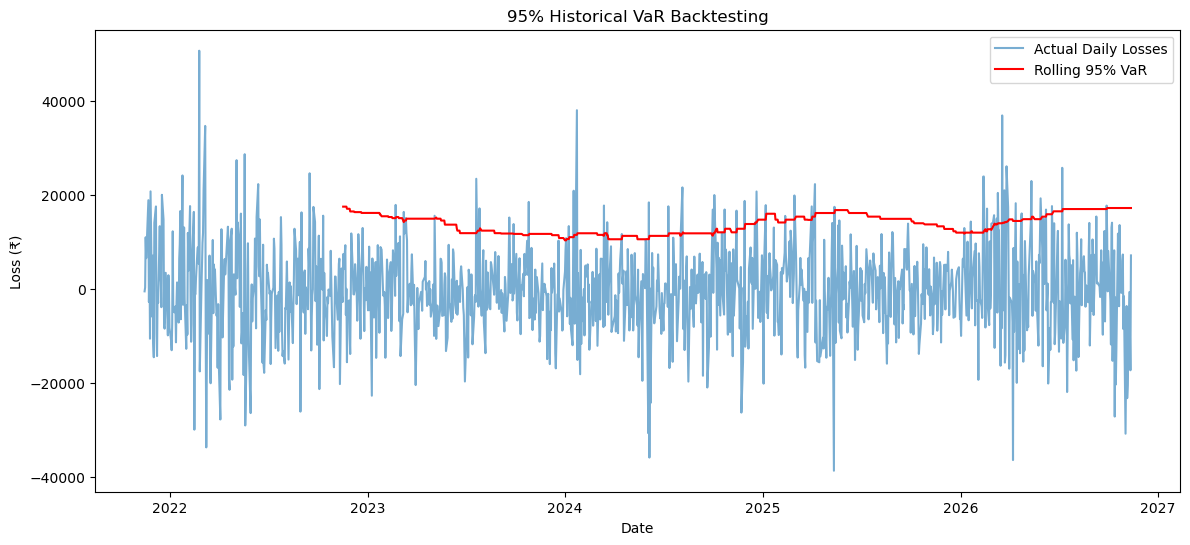

In [53]:
# visualize VaR backtesting

plt.figure(figsize=(14, 6))

plt.plot(
    historical_losses.index,
    historical_losses,
    label="Actual Daily Losses",
    alpha=0.6
)

plt.plot(
    rolling_var_95.index,
    rolling_var_95,
    label="Rolling 95% VaR",
    color="red"
)

plt.title("95% Historical VaR Backtesting")
plt.xlabel("Date")
plt.ylabel("Loss (₹)")
plt.legend()
plt.show()

<h3 style="color:#555;">9.4 Kupiec Proportion of Failures (POF) Test</h3>
<p>Statistically evaluating whether the observed VaR violation frequency is consistent with the expected frequency.</p>

<p>Importing the chi-square distribution from SciPy for statistical evaluation of VaR backtesting results.</p>
<p>Defining a function to perform the Kupiec Proportion of Failures test and evaluate whether observed VaR violation frequencies are consistent with expected frequencies.</p>

In [55]:
# defining the kupiec test function

from scipy.stats import chi2

def kupiec_test(violations, confidence_level):

    n = len(violations)
    x = violations.sum()

    p = 1 - confidence_level

    actual_rate = x / n

    likelihood_ratio = 2 * (
        (n - x) * np.log((1 - actual_rate) / (1 - p))
        + x * np.log(actual_rate / p)
    )

    p_value = 1 - chi2.cdf(likelihood_ratio, df=1)

    return likelihood_ratio, p_value

<p>Filtering the VaR violation series to include only days with valid rolling VaR estimates, excluding the initial estimation period.</p>
<p>Applying the Kupiec POF test to evaluate the 95% and 99% VaR models using their valid backtesting observations.</p>

In [66]:
# run the test

valid_95 = rolling_var_95.notna()
valid_99 = rolling_var_99.notna()

violations_95_valid = violations_95[valid_95]
violations_99_valid = violations_99[valid_99]

lr_95, p_value_95 = kupiec_test(violations_95_valid, 0.95)
lr_99, p_value_99 = kupiec_test(violations_99_valid, 0.99)

print("95% VaR - Likelihood Ratio:", lr_95)
print("95% VaR - P-value:", p_value_95)

print("99% VaR - Likelihood Ratio:", lr_99)
print("99% VaR - P-value:", p_value_99)

95% VaR - Likelihood Ratio: 1.551978200246655
95% VaR - P-value: 0.21284364240867526
99% VaR - Likelihood Ratio: 2.3446087644980445
99% VaR - P-value: 0.12571712090249565


<h4 style="color:#777;">Kupiec Test Interpretation</h4>

<p>Both p-values (0.2128 and 0.1257) are greater than the 0.05 significance level.</p>

<p>Therefore, we fail to reject the null hypothesis. The observed VaR violation frequencies are statistically consistent with the expected frequencies at both confidence levels.</p>

<p><i>Note: The Kupiec test evaluates violation frequency, not the independence of violations.</i></p>

<h2 style="color:#2874A6;">10. Stress Testing</h2>
<p>Evaluating portfolio resilience under hypothetical adverse market conditions using predefined stock-level return shocks.</p>

<p>Stress testing evaluates portfolio performance under hypothetical extreme market conditions by applying assumed negative returns to individual stocks.</p>

<p>This project considers three scenarios:</p>

<ul>
<li><b>Market Crash:</b> Significant declines across all five stocks.</li>
<li><b>Moderate Downturn:</b> Moderate declines across all five stocks.</li>
<li><b>Sector-Specific Shock:</b> A severe decline in the banking sector, with smaller declines in other sectors.</li>
</ul>

<p><i>Note: These hypothetical scenarios are used to assess portfolio vulnerability and are not predictions of future market movements.</i></p>

<h3 style="color:#555;">10.1 Stress Scenario Assumptions</h3>
<p>Defining hypothetical daily return shocks for each stock under three adverse market scenarios.</p>

In [61]:
# define the stress scenarios

stress_scenarios = {
    "Market Crash": [-0.15, -0.12, -0.10, -0.18, -0.15],
    "Moderate Downturn": [-0.08, -0.06, -0.05, -0.10, -0.08],
    "Sector-Specific Shock": [-0.20, -0.05, -0.03, -0.08, -0.06]
}

<p>The values represent hypothetical daily returns for the five stocks in the following order: HDFC Bank, TCS, Hindustan Unilever, Reliance Industries and Mahindra & Mahindra.</p>

<p>For example, <code>-0.15</code> represents a 15% assumed decline in a stock's value.</p>

<p><i>These scenarios are illustrative assumptions used to evaluate portfolio risk under adverse market conditions.</i></p>

<h3 style="color:#555;">10.2 Stressed Portfolio Return Calculation</h3>

<p>Calculating the weighted portfolio return under each hypothetical stress scenario using the assigned stock weights.</p>

In [62]:
# calculate stressed portfolio return

stress_results = {}

for scenario, returns in stress_scenarios.items():
    stressed_return = np.dot(weights, returns)
    stress_results[scenario] = stressed_return

<h3 style="color:#555;">10.3 Stress Testing Results</h3>
<p>Evaluating the financial impact of each stress scenario by converting stressed portfolio returns into estimated monetary losses.</p>

In [63]:
# calculate final impact

stress_summary = pd.DataFrame({
    "Portfolio Return": stress_results
})

stress_summary["Estimated Loss (₹)"] = (
    -stress_summary["Portfolio Return"] * portfolio_value
)

stress_summary

,Portfolio Return,Estimated Loss (₹)
Market Crash,-0.140,140000.0
Moderate Downturn,-0.074,74000.0
Sector-Specific Shock,-0.084,84000.0


<h3 style="color:#555;">10.4 Stress Testing Visualization</h3>
<p>Visualizing the estimated portfolio losses across the three hypothetical stress scenarios.</p>

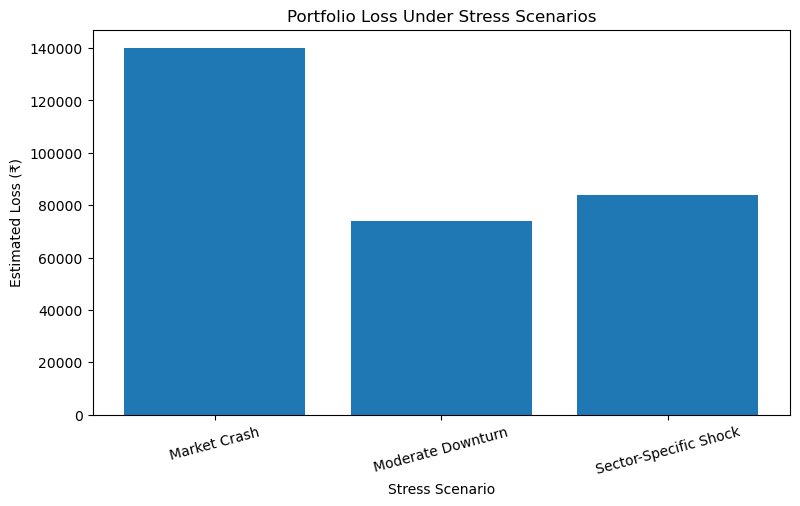

In [64]:
# visualize the stress test results

plt.figure(figsize=(9, 5))

plt.bar(
    stress_summary.index,
    stress_summary["Estimated Loss (₹)"]
)

plt.title("Portfolio Loss Under Stress Scenarios")

plt.xlabel("Stress Scenario")

plt.ylabel("Estimated Loss (₹)")

plt.xticks(rotation=15)

plt.show()

<h3 style="color:#555;">10.5 Stress Testing Interpretation</h3>

<p>The portfolio experienced its highest hypothetical loss under the Market Crash scenario (₹1,40,000), followed by the Sector-Specific Shock (₹84,000) and Moderate Downturn (₹74,000).</p>

<p>This demonstrates how adverse market conditions can affect the portfolio's value.</p>

<h2 style="color:#2874A6;">11. Final Portfolio Risk Summary</h2>
<p>Consolidating the key portfolio risk measurements, including Parametric VaR, Historical VaR, Monte Carlo VaR and Expected Shortfall.</p>

<p>This section consolidates the key risk measurements obtained from the portfolio analysis, including Value at Risk (VaR) and Expected Shortfall (ES) at 95% and 99% confidence levels.</p>

In [70]:
final_risk_summary = pd.DataFrame({
    "Risk Measure": [
        "Parametric VaR",
        "Historical VaR",
        "Monte Carlo VaR",
        "Historical Expected Shortfall"
    ],
    "95% Confidence (₹)": [
        var_95,
        historical_var_95,
        monte_carlo_var_95,
        expected_shortfall_95
    ],
    "99% Confidence (₹)": [
        var_99,
        historical_var_99,
        monte_carlo_var_99,
        expected_shortfall_99
    ]
})

final_risk_summary = (
    final_risk_summary
    .set_index("Risk Measure")
    .round(2)
)

final_risk_summary

,95% Confidence (₹),99% Confidence (₹)
Risk Measure,,
Parametric VaR,15354.18,21838.68
Historical VaR,15245.95,23224.73
Monte Carlo VaR,15460.82,22164.40
Historical Expected Shortfall,20558.86,29810.81


<h3 style="color:#555;">11.1 Risk Summary Interpretation</h3>

<ul>
<li>All three VaR methods produced relatively similar estimates at both confidence levels.</li>
<li>Historical Expected Shortfall was higher than VaR, representing the average loss beyond the estimated VaR threshold.</li>
<li>Risk estimates increased at the 99% confidence level, reflecting a more conservative assessment of potential losses.</li>
</ul>

<h2 style="color:#2874A6;">12. Portfolio Performance Over Time</h2>
<p>Tracking the historical growth and fluctuations of the hypothetical ₹10 lakh equal-weighted portfolio over the five-year period.</p>

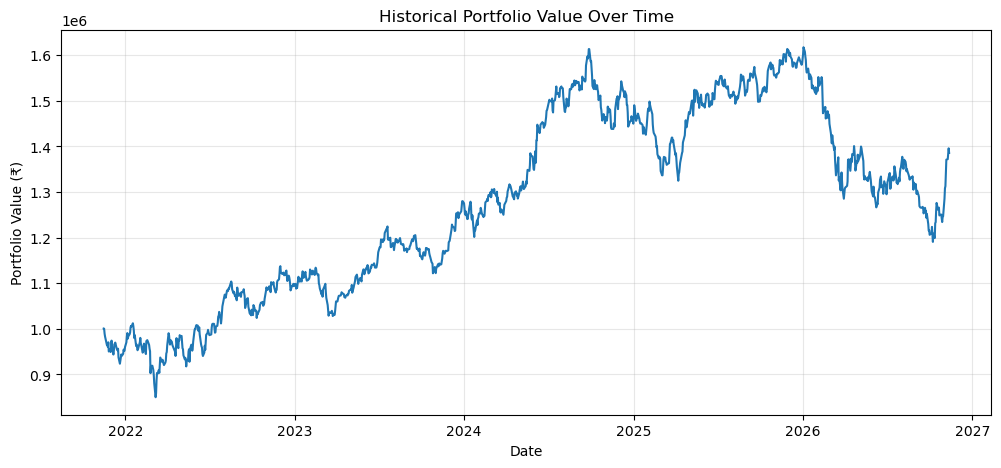

In [72]:
# portfolio performance over time

portfolio_value_history = (
    portfolio_value * (1 + portfolio_returns).cumprod()
)

plt.figure(figsize=(12, 5))

plt.plot(
    portfolio_value_history.index,
    portfolio_value_history
)

plt.title("Historical Portfolio Value Over Time")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (₹)")
plt.grid(True, alpha=0.3)
plt.show()

<h3 style="color:#555;">12.1 Portfolio Performance Interpretation</h3>

<p>The hypothetical portfolio gained approximately 39% over the five-year period, growing from ₹10 lakh to around ₹13.9 lakh.</p>

<p>The portfolio experienced several periods of growth and decline, including a significant drawdown of approximately 26% from its peak, followed by a recovery.</p>

<p>This illustrates the portfolio's historical performance and exposure to market fluctuations.</p>

For detailed explanations, methodology, assumptions and interpretation of results, refer to the accompanying project report.